In [1]:
import sys
sys.path.append('..')

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from src import utils

In [3]:
def A_T(b, T):
    """
    A_T(b) = 1 + b^2 + b^4 + ... + b^(2(T-1)).
    For large T, one might want a more efficient closed-form for geometric series.
    """
    return sum(b**(2*j) for j in range(T))

def E_eff(b, k, T):
    """
    Effective energy after minimizing out u:
        E_eff(b;k) = k^2 + 1/k^2 - [k*b^(T-1) + 1/k]^2 / A_T(b).
    """
    # Handle b=0 carefully to avoid zero-division (though in practice A_T(0)=1, so no issue).
    return k**2 + 1/k**2 - (k*b**(T-1) + 1/k)**2 / A_T(b, T)

def find_minimum_over_b(k, T, bmin=0.0, bmax=2.0, nb=2001):
    """
    Brute-force search for b in [bmin, bmax] that minimizes E_eff(b;k).
    Returns (b_opt, E_min).
    """
    b_vals = np.linspace(bmin, bmax, nb)
    e_vals = [E_eff(b, k, T) for b in b_vals]
    idx_min = np.argmin(e_vals)
    return b_vals[idx_min], e_vals[idx_min]

def find_u(b, k, T):
    u_star = (k*(b**(T-1)) + (1/k))/A_T(b,T)
    return u_star

def sweep_over_k(T, k_array):
    """
    For each k in k_array, finds the b that minimizes E_eff.
    Returns arrays of (k, b_min, E_min).
    """
    b_min_vals = []
    e_min_vals = []
    u_min_vals = []
    for k in k_array:
        b_opt, e_opt = find_minimum_over_b(k, T)
        u_opt = find_u(b_opt, k, T)
        b_min_vals.append(b_opt)
        e_min_vals.append(e_opt)
        u_min_vals.append(u_opt)
    return np.array(b_min_vals), np.array(e_min_vals), np.array(u_min_vals)

# T=3 (second-order transition)
k_vals = np.linspace(0.1, 2.0, 200)  # range of k values
b_min_T3, E_min_T3, u_min_T3 = sweep_over_k(3, k_vals)

# T=4 (first-order transition)
b_min_T4, E_min_T4, u_min_T4 = sweep_over_k(4, k_vals)

b_min_T100, E_min_T100, u_min_T100 = sweep_over_k(100, k_vals)

/var/folders/88/p8znsc4j3wj6nq2cj7m_l4xr0000gn/T/ipykernel_20952/3389713639.py:44: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


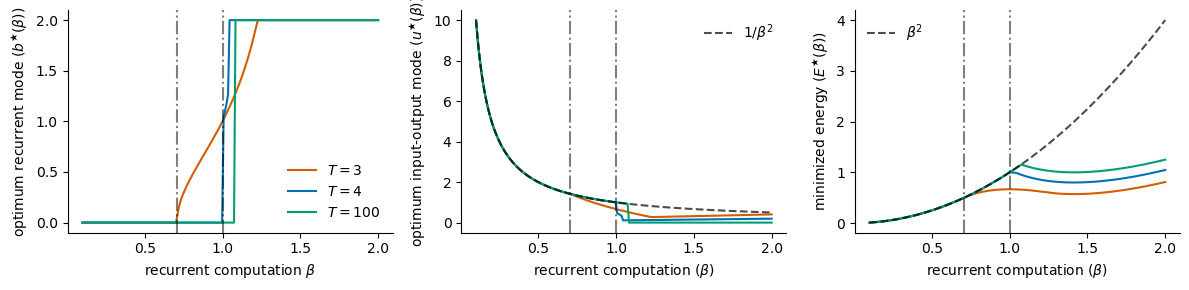

In [7]:
bc = utils.BlindColours()
blind_colors = bc.get_colours()
div_cmap = bc.get_div_cmap()

fig = plt.figure(figsize=(12,3), layout='constrained')
mosaic = """
abc
"""
    
axd = fig.subplot_mosaic(mosaic)
for ax in axd.values():
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.set_prop_cycle('color', blind_colors[:-1])
    
axd['a'].plot(k_vals, b_min_T3, label=r"$T=3$", color=blind_colors[0])
axd['a'].plot(k_vals, b_min_T4, label=r"$T=4$", color=blind_colors[1])
axd['a'].plot(k_vals, b_min_T100, label=r"$T=100$", color=blind_colors[2])
axd['a'].axvline(x=1/np.sqrt(2), color='k', ls='dashdot', alpha=0.5)
axd['a'].axvline(x=1, color='k', ls='dashdot', alpha=0.5)
axd['a'].set_xlabel(r"recurrent computation $\beta$")
axd['a'].set_ylabel(r"optimum recurrent mode ($b^\bigstar(\beta)$)")
axd['a'].legend(frameon=False)

axd['b'].plot(k_vals, u_min_T3)
axd['b'].plot(k_vals, u_min_T4)
axd['b'].plot(k_vals, u_min_T100)
axd['b'].axvline(x=1/np.sqrt(2), color='k', ls='dashdot', alpha=0.5)
axd['b'].axvline(x=1, color='k', ls='dashdot', alpha=0.5) 
axd['b'].plot(k_vals, 1/k_vals, color='black', ls='dashed', alpha=0.7, label=r'$1/\beta^2$')
axd['b'].set_xlabel(r"recurrent computation ($\beta$)")
axd['b'].set_ylabel(r"optimum input-output mode ($u^\bigstar(\beta)$)")
axd['b'].legend(frameon=False)

axd['c'].plot(k_vals, E_min_T3)
axd['c'].plot(k_vals, E_min_T4)
axd['c'].plot(k_vals, E_min_T100)
axd['c'].axvline(x=1/np.sqrt(2), color='k', ls='dashdot', alpha=0.5)
axd['c'].axvline(x=1, color='k', ls='dashdot', alpha=0.5)
axd['c'].plot(k_vals, k_vals**2, color='black', ls='dashed', alpha=0.7, label=r'$\beta^2$')
axd['c'].set_xlabel(r"recurrent computation ($\beta$)")
axd['c'].set_ylabel(r"minimized energy ($E^\bigstar(\beta)$)")
axd['c'].legend(frameon=False)   
fig.tight_layout()
# fig.savefig('paper_figs/landau_theory.svg', dpi=300, transparent=True)
# fig.savefig('paper_figs/landau_theory.png', dpi=300, transparent=True)
# fig.savefig('paper_figs/landau_theory.pdf', dpi=300, transparent=True)